In [12]:
import pandas as pd
dataset_Train=pd.read_csv(r"C:\Users\vilas\Downloads\Google_Stock_Price_Train.csv")

dataset_Train=dataset_Train.drop(['Close'],axis=1)

dataset_Train.head()

training_set=dataset_Train.iloc[:,1:2].values
 




In [13]:
#lstm model in 0-1 value work 

# apply minmax scaling
from sklearn.preprocessing import MinMaxScaler
mm=MinMaxScaler(feature_range=(0,1))
training_set_scaled=mm.fit_transform(training_set)
training_set_scaled.shape

 

(1258, 1)

In [14]:
# Create Data Structure # 20 Previous Days --> Next Day
#lstm is required previus output 
#creating a data structure with 60 timesstep and 1 output
import numpy as np
X_train=[]
y_train=[]
for i in range(20,1258):
    X_train.append(training_set_scaled[i-20:i,0])
    y_train.append(training_set_scaled[i,0])
    



X_train,y_train=np.array(X_train),np.array(y_train)


#converting in 3D ((1238, 20, 1))
# (samples, timesteps, features)
X_train=X_train.reshape(X_train.shape[0],
X_train.shape[1],1)
X_train.shape


 





(1238, 20, 1)

In [15]:
# Build LSTM Model
# buolding and training rnn code 
from keras.models import  Sequential
from keras.layers import Dense
from keras.layers import LSTM
from keras.layers import Dropout  # used for model is overfiting meas 0.2 is reduce neuron 20% 

# note: Activation is bydefault not use by programmer [Sigmoid]


In [54]:
regressor=Sequential()

# adding Layers 1                                #input_shape = (timesteps, features)
regressor.add(LSTM(units=50,return_sequences=True,input_shape=(X_train.shape[1],1)))
regressor.add(Dropout(0.2))
regressor.add(LSTM(units=50,return_sequences=False))
#return_sequences=True → outputs the full sequence (needed if another LSTM follows).

#return_sequences=False → outputs only the last hidden state (needed before Dense).
#regressor.add(Dropout(0.2))

regressor.add(Dense(units=1))



C:\Users\vilas\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [38]:
# model compile
regressor.compile(optimizer='adam',loss='mean_squared_error')

In [39]:
# fitting the rnn to training set 
regressor.fit(X_train,y_train,epochs=100,batch_size=32)

Epoch 1/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0353
Epoch 2/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0055
Epoch 3/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0046
Epoch 4/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0040
Epoch 5/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0038
Epoch 6/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0039
Epoch 7/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0040
Epoch 8/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0037
Epoch 9/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0035
Epoch 10/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0032
Epoch 11/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0029
Epoch 12/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0029
Epoch 13/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0030
Epoch 14/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0029
Epoch 15/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - lo

In [ ]:
dataset_test=pd.read_csv(r"C:\Users\vilas\Downloads\Google_Stock_Price_Test.csv")
dataset_test=dataset_test.drop(['Close'],axis=1)



In [ ]:
#prediction data on te
dataset_test=pd.read_csv(r"C:\Users\vilas\Downloads\Google_Stock_Price_Test.csv")

real_stock_price=dataset_test.iloc[:,1:2].values

#Combine train and test data

dataset_total=pd.concat((dataset_Train['Open'],dataset_test['Open']),axis=0)

print('dataset_total')

inputs=dataset_total[len(dataset_total)-len( )-60:].values

#1D array into a 2D array with 1 column.

inputs=inputs.reshape(-1,1)
inputs=mm.transform(inputs)


# Create Test Sequence

X_test=[]
for i in range(60,80):
    X_test.append(inputs[i-60:i,0])

X_test=np.array(X_test)
X_test=X_test.reshape(X_test.shape[0],X_test.shape[1],1)


# Prediction

predicted_stock_price=regressor.predict(X_test)


predicted_stock_price=mm.inverse_transform(predicted_stock_price)









dataset_total
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 648ms/step


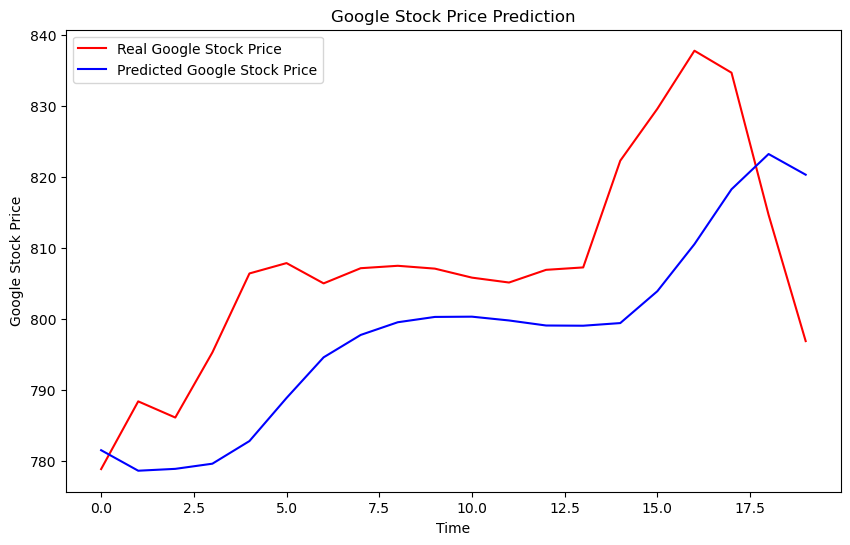

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.plot(real_stock_price, color='red', label='Real Google Stock Price')
plt.plot(predicted_stock_price, color='blue', label='Predicted Google Stock Price')

plt.title('Google Stock Price Prediction')
plt.xlabel('Time')
plt.ylabel('Google Stock Price')
plt.legend()

plt.show()

In [49]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

mae=mean_absolute_error(real_stock_price,predicted_stock_price)

print('mae:',mae)
mqe=mean_squared_error(real_stock_price,predicted_stock_price)

print('mqe:',mqe)


r_score=r2_score(real_stock_price,predicted_stock_price)
print("r2_score:",r_score)






mae: 13.197965209960937
mqe: 232.09470794753142
r2_score: -0.06788937810461193


In [53]:
#print Actual vs Predicted Values

comparison=pd.DataFrame({
    'actuval price': real_stock_price.flatten(),
    'predicted price':predicted_stock_price.flatten()
})

comparison


,actuval price,predicted price
0,778.81,781.474243
1,788.36,778.579834
2,786.08,778.843384
3,795.26,779.570984
4,806.40,782.764526
5,807.86,788.839111
6,805.00,794.570435
7,807.14,797.729370
8,807.48,799.518677
9,807.08,800.268372
